In [1]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

print("Library untuk Churn Model berhasil di-import!")

Library untuk Churn Model berhasil di-import!


In [4]:
# 1. Load Data Cleaned & Processed
df_orders = pd.read_csv('../data/cleaned/cleaned_orders.csv')
df_customers = pd.read_csv('../data/cleaned/cleaned_customers.csv')
df_items = pd.read_csv('../data/cleaned/cleaned_order_items.csv')
df_reviews = pd.read_csv('../data/cleaned/cleaned_order_reviews.csv')

# 2. Merge Dataset
df = df_orders.merge(df_customers[['customer_id', 'customer_unique_id', 'customer_state']], on='customer_id', how='inner')
df = df.merge(df_items[['order_id', 'price', 'freight_value']], on='order_id', how='inner')
df = df.merge(df_reviews[['order_id', 'review_score']], on='order_id', how='left')

# Datetime Conversion
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])
df['order_delivered_customer_date'] = pd.to_datetime(df['order_delivered_customer_date'])
df['order_estimated_delivery_date'] = pd.to_datetime(df['order_estimated_delivery_date'])

# Hitung Keterlambatan Pengiriman
df['delay_days'] = (df['order_delivered_customer_date'] - df['order_estimated_delivery_date']).dt.total_seconds() / (24 * 3600)
df['is_late'] = (df['delay_days'] > 0).astype(int)

# Tanggal Acuan Dataset (Max Date + 1 Hari)
max_date = df['order_purchase_timestamp'].max()

# 3. Feature Aggregation per Unique Customer
df_user = df.groupby('customer_unique_id').agg(
    last_purchase=('order_purchase_timestamp', 'max'),
    frequency=('order_id', 'nunique'),
    total_spend=('price', 'sum'),
    avg_price=('price', 'mean'),
    avg_freight=('freight_value', 'mean'),
    avg_review_score=('review_score', 'mean'),
    total_late_orders=('is_late', 'sum')
).reset_index()

# Recency hanya digunakan untuk MEMBENTUK TARGET VARIABLE, tidak dijadikan fitur!
df_user['recency_days'] = (max_date - df_user['last_purchase']).dt.days
df_user['is_churn'] = (df_user['recency_days'] > 90).astype(int)

# Fitur Interaksi Finansial
df_user['freight_ratio'] = df_user['avg_freight'] / (df_user['avg_price'] + 0.001)

# Impute missing values pada review score
df_user['avg_review_score'] = df_user['avg_review_score'].fillna(df_user['avg_review_score'].mean())

# HAPUS 'recency_days' DARI LIST FITUR
features = [
    'frequency', 'total_spend', 'avg_price', 
    'avg_freight', 'freight_ratio', 'avg_review_score', 'total_late_orders'
]

print(f"Total Unique Customer: {len(df_user)}")
print(f"Fitur Bebas Leakage ({len(features)}): {features}")

Total Unique Customer: 95420
Fitur Bebas Leakage (7): ['frequency', 'total_spend', 'avg_price', 'avg_freight', 'freight_ratio', 'avg_review_score', 'total_late_orders']


In [5]:
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score

X = df_user[features]
y = df_user['is_churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

lgb_churn = lgb.LGBMClassifier(
    n_estimators=300,
    learning_rate=0.03,
    max_depth=5,
    num_leaves=25,
    scale_pos_weight=0.25, # Menyesuaikan proporsi 80% churn vs 20% retained
    random_state=42,
    verbose=-1
)

lgb_churn.fit(X_train, y_train)

y_pred = lgb_churn.predict(X_test)
y_prob = lgb_churn.predict_proba(X_test)[:, 1]

print("=== EVALUASI MODEL CUSTOMER CHURN (VALID / NO LEAKAGE) ===")
print(classification_report(y_test, y_pred))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}")

=== EVALUASI MODEL CUSTOMER CHURN (VALID / NO LEAKAGE) ===
              precision    recall  f1-score   support

           0       0.42      0.71      0.53      3627
           1       0.92      0.77      0.84     15457

    accuracy                           0.76     19084
   macro avg       0.67      0.74      0.68     19084
weighted avg       0.82      0.76      0.78     19084

ROC-AUC Score: 0.8232


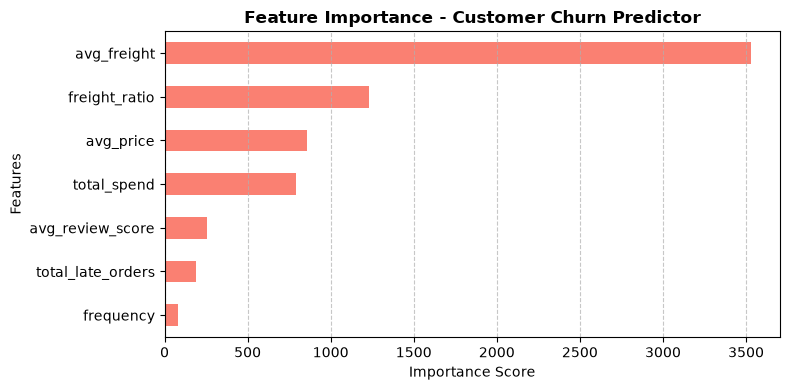

In [7]:
import matplotlib.pyplot as plt

importance = pd.Series(lgb_churn.feature_importances_, index=features).sort_values(ascending=True)

plt.figure(figsize=(8, 4))
importance.plot(kind='barh', color='salmon')
plt.title('Feature Importance - Customer Churn Predictor', fontsize=12, fontweight='bold')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [8]:
import joblib

# 1. Simpan Artefak Model ke /models/
joblib.dump(lgb_churn, '../models/customer_churn_lgb_model.pkl')
print("Model Churn berhasil disimpan ke folder /models/!")

# 2. Tambahkan Probabilitas Churn ke Seluruh Dataset
df_user['churn_risk_score'] = lgb_churn.predict_proba(df_user[features])[:, 1]
df_user['predicted_churn'] = (df_user['churn_risk_score'] > 0.5).astype(int)

# 3. Ekspor CSV ke data/processed/
export_cols = [
    'customer_unique_id', 'last_purchase', 'recency_days', 'frequency', 
    'total_spend', 'avg_review_score', 'churn_risk_score', 'predicted_churn'
]

df_export = df_user[export_cols].copy()
df_export.to_csv('../data/processed/customer_churn_predictions.csv', index=False)
print("File customer_churn_predictions.csv berhasil diperbarui di data/processed/!")

Model Churn berhasil disimpan ke folder /models/!
File customer_churn_predictions.csv berhasil diperbarui di data/processed/!
